In [1]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.io.ascii as ascii

from scipy.stats import binned_statistic

from tqdm import tqdm

from scipy.stats import norm

import matplotlib.lines as mlines

In [2]:
P21 = ascii.read("../sims/ROMAN/FITOPT000_ROMAN.FITRES")
P21_corr_max = ascii.read("../sims/ROMAN/FITOPT000_ROMAN_EBV_IGM_MAX.FITRES")
P21_corr_med = ascii.read("../sims/ROMAN/FITOPT000_ROMAN_EBV_IGM_MED.FITRES")
P21_corr_min = ascii.read("../sims/ROMAN/FITOPT000_ROMAN_EBV_IGM_MIN.FITRES")

In [3]:
def create_filt(file):
    
    filt = (np.abs(file['c']) < 0.3) & (np.abs(file['x1']) < 3) & (file['x1ERR'] < 1) & (file['PKMJDERR'] < 2) & (file['FITPROB'] > 0.001) & (file['SIM_AV'] > -9)
    
    return filt

In [4]:
print("******* Roman sims *******")
print("N\tz_min\tz_max")
print()
print("Total")
print(f"{len(P21[create_filt(P21)])}\t{np.min(P21['zHD'][create_filt(P21)]):.2f}\t{np.max(P21['zHD'][create_filt(P21)]):.2f}")
print()
print("Deep")
print(f"{len(P21[create_filt(P21)&(P21['FIELD']=='DEEP')])}\t{np.min(P21['zHD'][create_filt(P21)&(P21['FIELD']=='DEEP')]):.2f}\t{np.max(P21['zHD'][create_filt(P21)&(P21['FIELD']=='DEEP')]):.2f}")

******* Roman sims *******
N	z_min	z_max

Total
508177	0.10	3.00

Deep
152811	0.10	3.00


In [5]:
P21_shallow_filt = (np.abs(P21['c']) < 0.3) & (np.isin(P21['FIELD'],['WIDE'])) & (np.abs(P21['x1']) < 3) & (P21['x1ERR'] < 1) & (P21['PKMJDERR'] < 2) & (P21['FITPROB'] > 0.001) & (P21['SIM_AV'] > -9)
P21_corr_max_shallow_filt = (np.abs(P21_corr_max['c']) < 0.3) & (np.isin(P21_corr_max['FIELD'],['WIDE'])) & (np.abs(P21_corr_max['x1']) < 3) & (P21_corr_max['x1ERR'] < 1) & (P21_corr_max['PKMJDERR'] < 2) & (P21_corr_max['FITPROB'] > 0.001) & (P21_corr_max['SIM_AV'] > -9)

In [6]:
P21_deep_filt = (np.abs(P21['c']) < 0.3) & (np.isin(P21['FIELD'],['DEEP'])) & (np.abs(P21['x1']) < 3) & (P21['x1ERR'] < 1) & (P21['PKMJDERR'] < 2) & (P21['FITPROB'] > 0.001) & (P21['SIM_AV'] > -9)
P21_corr_max_deep_filt = (np.abs(P21_corr_max['c']) < 0.3) & (np.isin(P21_corr_max['FIELD'],['DEEP'])) & (np.abs(P21_corr_max['x1']) < 3) & (P21_corr_max['x1ERR'] < 1) & (P21_corr_max['PKMJDERR'] < 2) & (P21_corr_max['FITPROB'] > 0.001) & (P21_corr_max['SIM_AV'] > -9)

In [7]:
def bin_vals(x,y,num_bins=30):
    bin_edges = np.linspace(np.min(x),np.max(x),num_bins+1)
    
    bin_means, _, _ = binned_statistic(x,y,statistic='median',bins=bin_edges)
    bin_std, _, _ = binned_statistic(x,y,statistic='std',bins=bin_edges)
    bin_count, _, _ = binned_statistic(x,y,statistic='count',bins=bin_edges)
    
    bin_std_errors = bin_std/np.sqrt(bin_count)
    
    return bin_edges, bin_means, bin_std_errors

# Roman Figure 1 

In [8]:
bin_edges = np.arange(np.min(P21_corr_max['zHD'][P21_corr_max_deep_filt]),np.max(P21_corr_max['zHD'][P21_corr_max_deep_filt]),0.06)

In [9]:
bin_count_P21_shallow, _, _ = binned_statistic(P21['zHD'][P21_shallow_filt],P21['zHD'][P21_shallow_filt],statistic='count',bins=bin_edges)

bin_count_P21_corr_max_shallow, _, _ = binned_statistic(P21_corr_max['zHD'][P21_corr_max_shallow_filt],P21_corr_max['zHD'][P21_corr_max_shallow_filt],statistic='count',bins=bin_edges)

In [10]:
bin_count_P21_deep, _, _ = binned_statistic(P21['zHD'][P21_deep_filt],P21['zHD'][P21_deep_filt],statistic='count',bins=bin_edges)

bin_count_P21_corr_max_deep, _, _ = binned_statistic(P21_corr_max['zHD'][P21_corr_max_deep_filt],P21_corr_max['zHD'][P21_corr_max_deep_filt],statistic='count',bins=bin_edges)

In [11]:
def find_drop(x,y):
    small_drop = True
    i=0
    while (small_drop == True):
        if (y[i]-y[i+1]) > 0.01:
            z_drop = (x[i]+x[i+1])/2
            small_drop = False
        i+=1
        
    return z_drop

In [12]:
bin_zs = (bin_edges[:-1] + bin_edges[1:])/2

z_drop_shallow = find_drop(bin_zs,bin_count_P21_corr_max_shallow/bin_count_P21_shallow)
z_drop_deep = find_drop(bin_zs,bin_count_P21_corr_max_deep/bin_count_P21_deep)

/var/folders/n3/wyq2p73j1vndxxx0_dyk42540000gp/T/ipykernel_628/1317632745.py:3: RuntimeWarning: invalid value encountered in divide
  z_drop_shallow = find_drop(bin_zs,bin_count_P21_corr_max_shallow/bin_count_P21_shallow)


In [13]:
print(z_drop_shallow)
print(z_drop_deep)

1.1800000000000002
2.14


In [14]:
bin_edges_P21_shallow, c_bin_means_P21_shallow, c_bin_std_P21_shallow = bin_vals(P21['zHD'][P21_shallow_filt],P21['c'][P21_shallow_filt],num_bins=len(bin_zs))
bin_edges_P21_corr_max_shallow, c_bin_means_P21_corr_max_shallow, c_bin_std_P21_corr_max_shallow = bin_vals(P21_corr_max['zHD'][P21_corr_max_shallow_filt],P21_corr_max['c'][P21_corr_max_shallow_filt],num_bins=len(bin_zs))

In [15]:
bin_edges_P21_deep, c_bin_means_P21_deep, c_bin_std_P21_deep = bin_vals(P21['zHD'][P21_deep_filt],P21['c'][P21_deep_filt],num_bins=len(bin_zs))
bin_edges_P21_corr_max_deep, c_bin_means_P21_corr_max_deep, c_bin_std_P21_corr_max_deep = bin_vals(P21_corr_max['zHD'][P21_corr_max_deep_filt],P21_corr_max['c'][P21_corr_max_deep_filt],num_bins=len(bin_zs))

/var/folders/n3/wyq2p73j1vndxxx0_dyk42540000gp/T/ipykernel_628/1784245809.py:6: RuntimeWarning: invalid value encountered in divide
  bin_count_P21_corr_max_shallow[:-9]/bin_count_P21_shallow[:-9],label='Shallow',zorder=3)


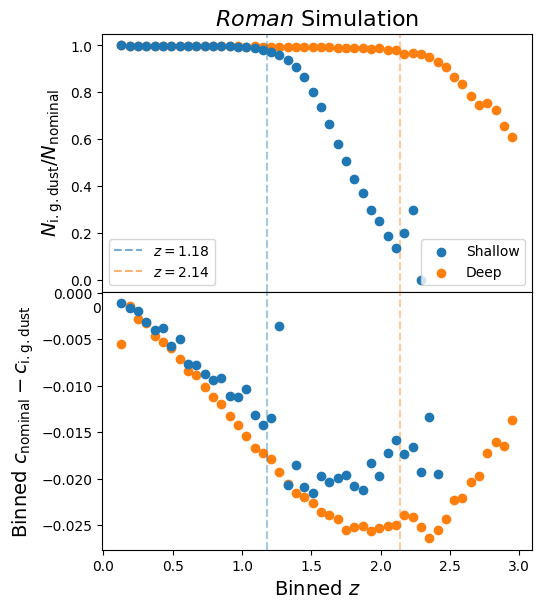

In [16]:
fig = plt.figure(figsize=(5,6))

ax1 = fig.add_axes([0.08, 0.52, 0.86, 0.43])

plt.scatter(bin_zs[:-9],
            bin_count_P21_corr_max_shallow[:-9]/bin_count_P21_shallow[:-9],label='Shallow',zorder=3)
plt.scatter(bin_zs,
            bin_count_P21_corr_max_deep/bin_count_P21_deep,label='Deep',zorder=2)
legend1 = plt.legend(loc='lower right')

plt.axvline(x=z_drop_shallow,
            color='C0',ls='--',alpha=0.4)
plt.axvline(x=z_drop_deep,
            color='C1',ls='--',alpha=0.4)

ax = plt.gca()
blue_dotted = mlines.Line2D([], [], color="C0", linestyle="--", label=f"$z={z_drop_shallow:.2f}$",alpha=0.6)
orange_dotted = mlines.Line2D([], [], color="C1", linestyle="--", label=f"$z={z_drop_deep:.2f}$",alpha=0.6)
legend2 = ax.legend(handles=[blue_dotted,orange_dotted],loc='lower left')

ax.add_artist(legend1)

plt.title("$Roman$ Simulation",fontsize=16)
plt.ylabel("$N_\mathrm{i.g. dust}/N_\mathrm{nominal}$",fontsize=14)

ax2 = fig.add_axes([0.08, 0.09, 0.86, 0.43])
plt.scatter(bin_zs[:-9],c_bin_means_P21_shallow[:-9]-c_bin_means_P21_corr_max_shallow[:-9],zorder=3)
plt.scatter(bin_zs,c_bin_means_P21_deep-c_bin_means_P21_corr_max_deep,zorder=2)
plt.xlabel("Binned $z$",fontsize=14)
plt.ylabel("Binned $c_\mathrm{nominal}-c_\mathrm{i.g. dust}$",fontsize=14)

plt.axvline(x=z_drop_shallow,
            color='C0',ls='--',alpha=0.4)
plt.axvline(x=z_drop_deep,
            color='C1',ls='--',alpha=0.4)


# plt.savefig("pngs/ROMAN_sim_compare.png",bbox_inches='tight')
# plt.savefig("pdfs/ROMAN_sim_compare.pdf",bbox_inches='tight')
plt.show()

# Roman Figure 2

In [17]:
data = ascii.read("../sims/ROMAN/FITOPT000_ROMAN_DATA.FITRES")

In [18]:
print("******* Roman sims *******")
print("N\tz_min\tz_max")
print()
print("Total")
print(f"{len(data[create_filt(data)])}\t{np.min(data['zHD'][create_filt(data)]):.2f}\t{np.max(data['zHD'][create_filt(data)]):.2f}")
print()
print("Deep")
print(f"{len(data[create_filt(data)&(data['FIELD']=='DEEP')])}\t{np.min(data['zHD'][create_filt(data)&(data['FIELD']=='DEEP')]):.2f}\t{np.max(data['zHD'][create_filt(data)&(data['FIELD']=='DEEP')]):.2f}")

******* Roman sims *******
N	z_min	z_max

Total
12654	0.10	3.00

Deep
3799	0.13	3.00


In [19]:
""" MEANS splitting by field shallow/deep """
def calc_c_vs_z(data,sims_list,zmin=0.0,zmax=0.1,delta=0.1,N=30,offset=0):
    sim = sims_list[0]
    
    zmin = 0.2
    zmax = 0.3
    delta = 0.1 #was at 0.2 and zmax at 0.3

    z_means = []
    shallow_data_c_means = []
    shallow_data_c_stds = []

    shallow_sim_c_means = []
    shallow_sim_c_stds = []
    
    deep_data_c_means = []
    deep_data_c_stds = []

    deep_sim_c_means = []
    deep_sim_c_stds = []

    
    total_N_data = 0

    for i in range(N): #was at 5
        shallow_data_z_filt = (data['zHD'] <= z_drop_shallow) & (data['zHD'] > zmin) & (data['zHD'] <= zmax) & (np.isin(data['FIELD'],['WIDE'])) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)

        bins = np.arange(-0.3,0.35,0.05)

        #data  
        if (z_drop_shallow - zmin) > 0.04:
            shallow_data_c_means.append(np.mean(data['c'][shallow_data_z_filt]))
            shallow_data_c_stds.append(np.std(data['c'][shallow_data_z_filt])/np.sqrt(len(data['c'][shallow_data_z_filt])))

        deep_data_z_filt = (data['zHD'] <= z_drop_deep) & (data['zHD'] > zmin) & (data['zHD'] <= zmax) & (np.isin(data['FIELD'],['DEEP'])) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)

        if (z_drop_deep - zmin) > 0.04:
            deep_data_c_means.append(np.mean(data['c'][deep_data_z_filt]))
            deep_data_c_stds.append(np.std(data['c'][deep_data_z_filt])/np.sqrt(len(data['c'][deep_data_z_filt])))

        total_N_data+=len(data[shallow_data_z_filt])
        total_N_data+=len(data[deep_data_z_filt])

        
        #sims
        shallow_sim_z_filt = (sim['zHD'] <= z_drop_shallow) & (sim['zHD'] > zmin) & (sim['zHD'] <= zmax) & (np.abs(sim['c']) < 0.3) & (np.isin(sim['FIELD'],['WIDE'])) & (np.abs(sim['x1']) < 3) & (sim['x1ERR'] < 1) & (sim['PKMJDERR'] < 2) & (sim['FITPROB'] > 0.001) & (sim['SIM_AV'] > -9)

        if (z_drop_shallow - zmin) > 0.04:
            shallow_sim_c_means.append(np.mean(sim['c'][shallow_sim_z_filt])+offset)
            shallow_sim_c_stds.append(np.std(sim['c'][shallow_sim_z_filt])/np.sqrt(len(sim['c'][shallow_sim_z_filt])))

        deep_sim_z_filt = (sim['zHD'] <= z_drop_deep) & (sim['zHD'] > zmin) & (sim['zHD'] <= zmax) & (np.abs(sim['c']) < 0.3) & (np.isin(sim['FIELD'],['DEEP'])) & (np.abs(sim['x1']) < 3) & (sim['x1ERR'] < 1) & (sim['PKMJDERR'] < 2) & (sim['FITPROB'] > 0.001) & (sim['SIM_AV'] > -9)

        if (z_drop_deep - zmin) > 0.04:
            deep_sim_c_means.append(np.mean(sim['c'][deep_sim_z_filt])+offset)
            deep_sim_c_stds.append(np.std(sim['c'][deep_sim_z_filt])/np.sqrt(len(sim['c'][deep_sim_z_filt])))

        z_means.append((zmin+zmax)/2)                           


        zmin+=delta
        zmax+=delta
    print(total_N_data)
    
    
    z_means = np.array(z_means)
    shallow_data_c_means = np.array(shallow_data_c_means)
    shallow_data_c_stds = np.array(shallow_data_c_stds)
    shallow_sim_c_means = np.array(shallow_sim_c_means)
    shallow_sim_c_stds = np.array(shallow_sim_c_stds)
    
    deep_data_c_means = np.array(deep_data_c_means)
    deep_data_c_stds = np.array(deep_data_c_stds)
    deep_sim_c_means = np.array(deep_sim_c_means)
    deep_sim_c_stds = np.array(deep_sim_c_stds)
    
    return (z_means,shallow_data_c_means,shallow_data_c_stds,shallow_sim_c_means,shallow_sim_c_stds,deep_data_c_means,deep_data_c_stds,deep_sim_c_means,deep_sim_c_stds)

In [20]:
def plot_c_vs_z(z,c,cerr=[],label='',sim=True,color='C0'):
    """ plot one at a time (don't say plt.show()) """
    #sims
    if sim == True:
        plt.plot(z,c,label=label,color=color)
        if len(cerr)>0:
            plt.errorbar(z,c,yerr=cerr,ls='none',zorder=1,alpha=0.8,color=color,capsize=2,lw=2)
    #data
    else:
        plt.scatter(z,c,label=label,color=color)
        if len(cerr)>0:
            plt.errorbar(z,c,yerr=cerr,ls='none',zorder=1,alpha=0.4,color=color)
        
    
        
    plt.xlabel("$z$",fontsize=16)
    plt.ylabel("mean $c$",fontsize=16)
#     plt.xlim(0.0,1.1)
#     plt.ylim(-0.12,0.07)
    plt.legend(loc='upper right',fontsize=16)

In [21]:
def chi2(data,sim,data_err):
    return np.sum((np.array(data)-np.array(sim))**2/np.array(data_err)**2)

In [22]:
mz,sdc,sdc_s,ssc,ssc_s,ddc,ddc_s,dsc,dsc_s = calc_c_vs_z(data,[P21],zmin=0.1,zmax=0.2)
_,_,_,ssc2,ssc_s2,_,_,dsc2,dsc_s2 = calc_c_vs_z(data,[P21],zmin=0.1,zmax=0.2)
_,_,_,ssc3,ssc_s3,_,_,dsc3,dsc_s3 = calc_c_vs_z(data,[P21_corr_max],zmin=0.1,zmax=0.2)

8780
8780
8780


In [23]:
#Fit for an offset between Data and Sim

def weighted_mean_difference(A, B, sigma_A, sigma_B):
    """
    Compute the weighted mean difference between two datasets A and B,
    taking into account their uncertainties sigma_A and sigma_B.

    Parameters:
    A (array-like): First set of values.
    B (array-like): Second set of values.
    sigma_A (array-like): Uncertainties associated with A.
    sigma_B (array-like): Uncertainties associated with B.

    Returns:
    tuple: (weighted mean difference, uncertainty of the weighted mean)
    """
    # Compute differences and propagated uncertainties
    D = np.array(A) - np.array(B)
    sigma_D = np.sqrt(np.array(sigma_A)**2 + np.array(sigma_B)**2)

    # Compute weighted mean difference
    weights = 1 / sigma_D**2
    D_mean = np.sum(D * weights) / np.sum(weights)

    # Compute uncertainty of the weighted mean
    sigma_D_mean = np.sqrt(1 / np.sum(weights))

    return D_mean, sigma_D_mean

In [24]:
wmd2 = weighted_mean_difference(dsc2,ddc,dsc_s2,ddc_s)[0]
wmd3 = weighted_mean_difference(dsc3,ddc,dsc_s3,ddc_s)[0]
print(wmd2)
print(wmd3)

-0.00046681472238904417
0.017546198668120315


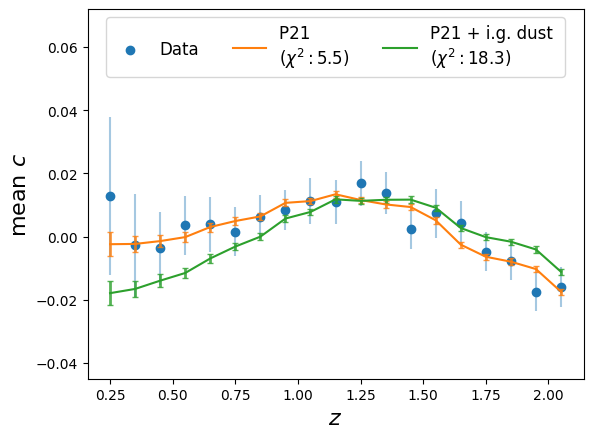

In [25]:
# plt.title("Deep",fontsize=18)
plot_c_vs_z(mz[0:len(ddc)],ddc,cerr=ddc_s,label='Data',sim=False)
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc2)-wmd2,cerr=dsc_s2,label=f'Sim \n($\chi^2:{chi2(ddc,dsc2-wmd2,ddc_s):.1f}$)',color='C1')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc3)-wmd3,cerr=dsc_s3,label=f'Sim + i.g. dust \n($\chi^2:{chi2(ddc,dsc3-wmd3,ddc_s):.1f}$)',color='C2')
plt.legend(loc='upper center',fontsize=12,ncol=3)
# ax2.get_legend().remove()
plt.ylim(-0.045,0.072)
# plt.xlim(0,1)

# plt.savefig("pngs/DES_compare_c_vs_z.png",bbox_inches='tight')
# plt.savefig("pdfs/DES_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()

## - Divisions of i.g. dust too for Roman

In [26]:
_,_,_,ssc4,ssc_s4,_,_,dsc4,dsc_s4 = calc_c_vs_z(data,[P21_corr_med],zmin=0.1,zmax=0.2)
_,_,_,ssc5,ssc_s5,_,_,dsc5,dsc_s5 = calc_c_vs_z(data,[P21_corr_min],zmin=0.1,zmax=0.2)

8780
8780


In [27]:
wmd4 = weighted_mean_difference(dsc4,ddc,dsc_s4,ddc_s)[0]
wmd5 = weighted_mean_difference(dsc5,ddc,dsc_s5,ddc_s)[0]
print(wmd4)
print(wmd5)

0.012139729818665885
0.006392959261178684


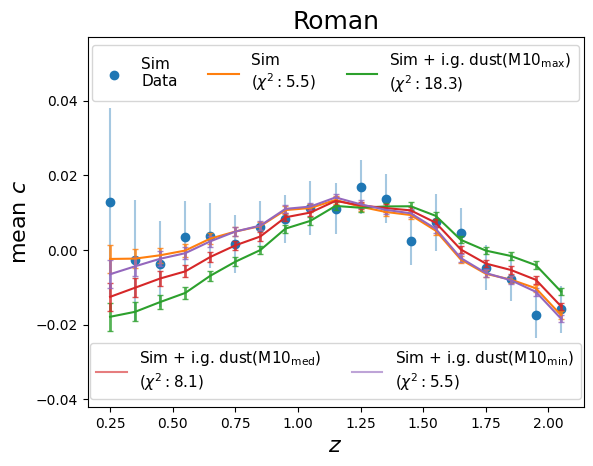

In [33]:
plt.title("Roman",fontsize=18)
plot_c_vs_z(mz[0:len(ddc)],ddc,cerr=ddc_s,label='Sim\nData',
            sim=False)
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc2)-wmd2,cerr=dsc_s2,label=f'Sim \n($\chi^2:{chi2(ddc,dsc2-wmd2,ddc_s):.1f}$)',
            color='C1')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc3)-wmd3,cerr=dsc_s3,label=f'Sim + i.g. dust(M10$_\mathrm{{max}}$) \n($\chi^2:{chi2(ddc,dsc3-wmd3,ddc_s):.1f}$)',
            color='C2')

legend1 = plt.legend(loc="upper center",ncol=3,fontsize=11)

plot_c_vs_z(mz[0:len(ddc)],np.array(dsc4)-wmd4,cerr=dsc_s4,label=None,#f'P21 + 3 x i.g. dust \n($\chi^2:{chi2(ddc,dsc4,ddc_s):.1f}$)',
            color='C3')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc5)-wmd5,cerr=dsc_s5,label=None,#f'P21 + 5 x i.g. dust \n($\chi^2:{chi2(ddc,dsc5,ddc_s):.1f}$)',
            color='C4')
ax = plt.gca()
blue_dotted = mlines.Line2D([], [], color="C3", linestyle="-", label=f'Sim + i.g. dust(M10$_\mathrm{{med}}$)\n($\chi^2:{chi2(ddc,dsc4-wmd4,ddc_s):.1f}$)',alpha=0.6)
orange_dotted = mlines.Line2D([], [], color="C4", linestyle="-", label=f'Sim + i.g. dust(M10$_\mathrm{{min}}$) \n($\chi^2:{chi2(ddc,dsc5-wmd5,ddc_s):.1f}$)',alpha=0.6)
legend2 = ax.legend(handles=[blue_dotted,orange_dotted],loc='lower center',ncol=2,fontsize=11)
# legend2 = ax.legend(handles=[blue_dotted],loc='lower center',ncol=2,fontsize=11)


ax.add_artist(legend1)

plt.ylim(-0.042,0.057)
# plt.xlim(0,1)

# plt.savefig("pngs/ROMAN_all_compare_c_vs_z.png",bbox_inches='tight')
# plt.savefig("pdfs/ROMAN_all_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()

In [38]:
swmd2 = weighted_mean_difference(ssc2,sdc,ssc_s2,sdc_s)[0]
swmd3 = weighted_mean_difference(ssc3,sdc,ssc_s3,sdc_s)[0]
swmd4 = weighted_mean_difference(ssc4,sdc,ssc_s4,sdc_s)[0]
swmd5 = weighted_mean_difference(ssc5,sdc,ssc_s5,sdc_s)[0]

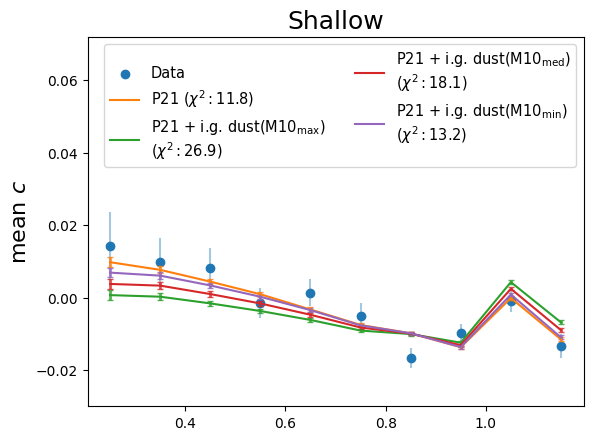

In [43]:
plt.title("Shallow",fontsize=18)
plot_c_vs_z(mz[0:len(sdc)],sdc,cerr=sdc_s,label='Data',sim=False)
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc2)-swmd2,cerr=1*np.array(ssc_s2),label=f'P21 ($\chi^2:{chi2(sdc,ssc2-swmd2,sdc_s):.1f}$)',color='C1')
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc3)-swmd3,cerr=np.array(ssc_s3),label=f'P21 + i.g. dust(M10$_\mathrm{{max}}$)\n($\chi^2:{chi2(sdc,ssc3-swmd3,sdc_s):.1f}$)',color='C2')

plot_c_vs_z(mz[0:len(sdc)],np.array(ssc4)-swmd4,cerr=np.array(ssc_s4),label=f'P21 + i.g. dust(M10$_\mathrm{{med}}$)\n($\chi^2:{chi2(sdc,ssc4-swmd4,sdc_s):.1f}$)',color='C3')
plot_c_vs_z(mz[0:len(sdc)],np.array(ssc5)-swmd5,cerr=np.array(ssc_s5),label=f'P21 + i.g. dust(M10$_\mathrm{{min}}$)\n($\chi^2:{chi2(sdc,ssc5-swmd5,sdc_s):.1f}$)',color='C4')
plt.xlabel("")
plt.legend(loc='upper right',fontsize=10.5,ncol=2)
plt.ylim(-0.03,0.072)
plt.show()

In [45]:
def plot_mu_dif(nodust,dust):
    mures = nodust['mB']+0.14*nodust['x1']-3.1*nodust['c']+19.35-nodust['SIM_DLMAG']
    corr_mures = dust['mB']+0.14*dust['x1']-3.1*dust['c']+19.35-dust['SIM_DLMAG']

    bin_edges1, mu_bin_means1, mu_bin_std1 = bin_vals(nodust['zHD'],mures)
    bin_edges2, mu_bin_means2, mu_bin_std2 = bin_vals(dust['zHD'],corr_mures)

    plt.errorbar((bin_edges1[:-1] + bin_edges1[1:]) / 2, mu_bin_means1,yerr=mu_bin_std1,
                 ls = 'none',marker='s', c='C3', label='nodust')
    plt.errorbar((bin_edges2[:-1] + bin_edges2[1:]) / 2, mu_bin_means2,yerr=mu_bin_std2,
                 ls = 'none',marker='s', c='C4', label='dust')

    plt.ylabel("$\mu_\mathrm{res}$ (mag)",fontsize=14)
    plt.xlabel("$z$",fontsize=14)
    plt.legend()

    plt.show()
    
    plt.figure(figsize=(6,4.5))
    plt.scatter((bin_edges1[:-1] + bin_edges1[1:]) / 2,mu_bin_means2-mu_bin_means1,label="$\mu_\mathrm{i.g.~dust} - \mu_\mathrm{nom.}$",zorder=20)
    plt.errorbar((bin_edges1[:-1] + bin_edges1[1:]) / 2,mu_bin_means2-mu_bin_means1,
                 yerr=np.sqrt(mu_bin_std1**2+mu_bin_std2**2),
                 ls = 'none',zorder=2)
    # plt.scatter((bin_edges1[:-1] + bin_edges1[1:]) / 2,1*(bin_means3-bin_means1),label="BS20_corr - BS20")
    plt.xlabel("$z$",fontsize=14)
    plt.ylabel("$\Delta\mu$ (mag)",fontsize=14)
    plt.legend(fontsize=14,loc='upper left')
    plt.axhline(c='k',ls='--',zorder=1)
    plt.ylim(-0.005,0.03)
    # plt.savefig("pdfs/mu_from_igdust.pdf",bbox_inches='tight')
    # plt.savefig("pngs/mu_from_igdust.png",bbox_inches='tight')
    plt.show()

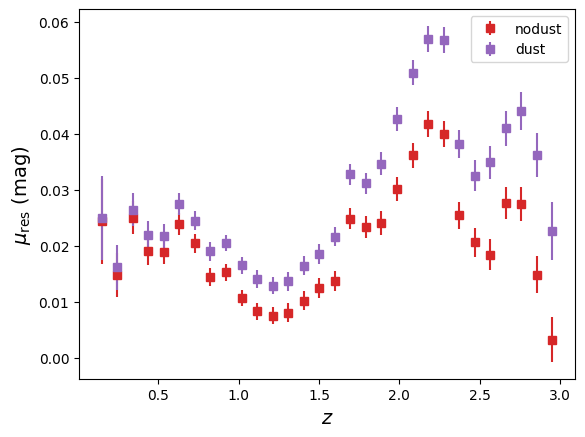

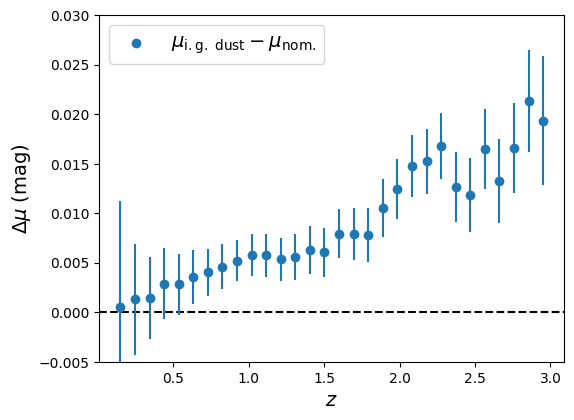

In [47]:
plot_mu_dif(P21[create_filt(P21)&(np.isin(P21['FIELD'],['DEEP']))],P21_corr_max[create_filt(P21_corr_max)&(np.isin(P21_corr_max['FIELD'],['DEEP']))])


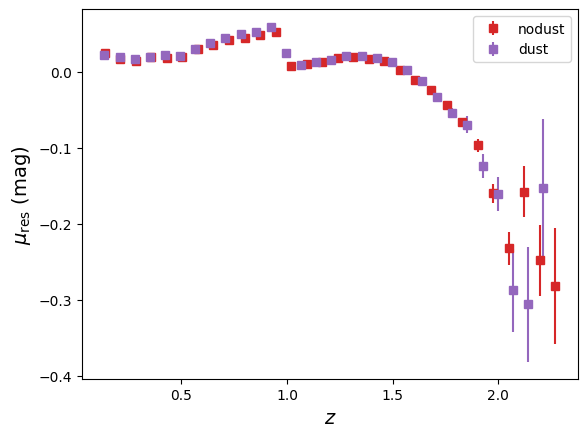

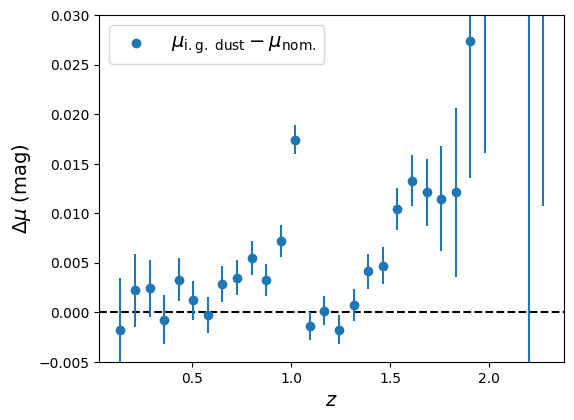

In [48]:
plot_mu_dif(P21[create_filt(P21)&(np.isin(P21['FIELD'],['WIDE']))],P21_corr_max[create_filt(P21_corr_max)&(np.isin(P21_corr_max['FIELD'],['WIDE']))])


# Old

In [32]:
# z_thresh = 0.5
# P21_filt = (P21['zHD'] < z_thresh) & (np.abs(P21['c']) < 0.3) & (np.abs(P21['x1']) < 3) & (P21['x1ERR'] < 1) & (P21['PKMJDERR'] < 2) & (P21['FITPROB'] > 0.001) & (P21['SIM_AV'] > -9)
# P21_c_mean = np.mean(P21['c'][P21_filt])

# data_filt = (data['zHD'] < z_thresh) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)
# data_c_mean = np.mean(data['c'][data_filt])

# P21_corr_filt = (P21_corr['zHD'] < z_thresh) & (np.abs(P21_corr['c']) < 0.3) & (np.abs(P21_corr['x1']) < 3) & (P21_corr['x1ERR'] < 1) & (P21_corr['PKMJDERR'] < 2) & (P21_corr['FITPROB'] > 0.001) & (P21_corr['SIM_AV'] > -9)
# P21_corr_c_mean = np.mean(P21_corr['c'][P21_corr_filt])

# mz,sdc,sdc_s,ssc,ssc_s,ddc,ddc_s,dsc,dsc_s = calc_c_vs_z(data,[P21],zmin=0.1,zmax=0.2)
# _,_,_,ssc2,ssc_s2,_,_,dsc2,dsc_s2 = calc_c_vs_z(data,[P21],zmin=0.1,zmax=0.2,offset=data_c_mean-P21_c_mean)
# _,_,_,ssc3,ssc_s3,_,_,dsc3,dsc_s3 = calc_c_vs_z(data,[P21_corr],zmin=0.1,zmax=0.2,offset=data_c_mean-P21_corr_c_mean)

100%|██████████████████████████████████████████| 30/30 [00:00<00:00, 103.98it/s]


8969


100%|██████████████████████████████████████████| 30/30 [00:00<00:00, 105.29it/s]


8969


100%|██████████████████████████████████████████| 30/30 [00:00<00:00, 107.23it/s]

8969


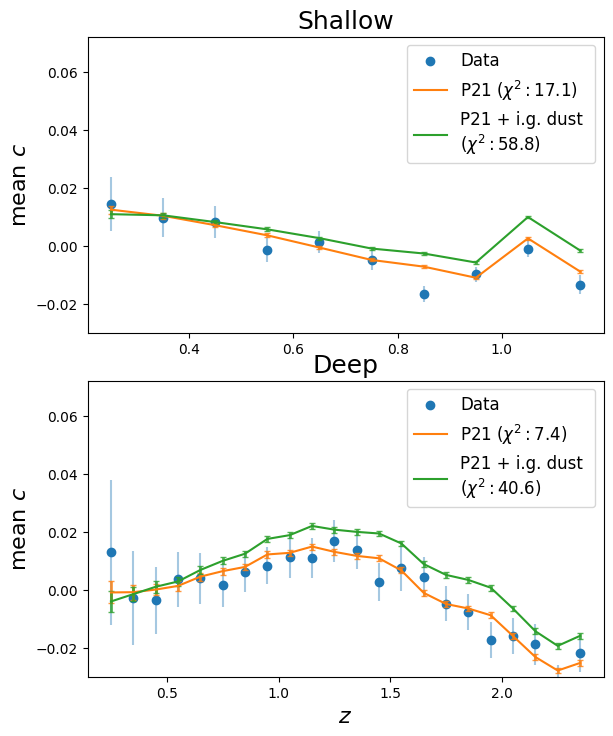

In [33]:
# fig = plt.figure(figsize=(6,8))

# ax1 = fig.add_axes([0.08, 0.52, 0.86, 0.37])
# plt.title("Shallow",fontsize=18)
# plot_c_vs_z(mz[0:len(sdc)],sdc,cerr=sdc_s,label='Data',sim=False)
# plot_c_vs_z(mz[0:len(sdc)],np.array(ssc2),cerr=1*np.array(ssc_s2),label=f'P21 ($\chi^2:{chi2(sdc,ssc2,sdc_s):.1f}$)',color='C1')
# plot_c_vs_z(mz[0:len(sdc)],np.array(ssc3),cerr=np.array(ssc_s3),label=f'P21 + i.g. dust \n($\chi^2:{chi2(sdc,ssc3,sdc_s):.1f}$)',color='C2')
# plt.xlabel("")
# plt.legend(loc='upper right',fontsize=12)
# plt.ylim(-0.03,0.072)
# # plt.xlim(0,1)

# ax2 = fig.add_axes([0.08, 0.09, 0.86, 0.37])
# plt.title("Deep",fontsize=18)
# plot_c_vs_z(mz[0:len(ddc)],ddc,cerr=ddc_s,label='Data',sim=False)
# plot_c_vs_z(mz[0:len(ddc)],np.array(dsc2),cerr=dsc_s2,label=f'P21 ($\chi^2:{chi2(ddc,dsc2,ddc_s):.1f}$)',color='C1')
# plot_c_vs_z(mz[0:len(ddc)],np.array(dsc3),cerr=dsc_s3,label=f'P21 + i.g. dust \n($\chi^2:{chi2(ddc,dsc3,ddc_s):.1f}$)',color='C2')
# plt.legend(loc='upper right',fontsize=12)
# # ax2.get_legend().remove()
# plt.ylim(-0.03,0.072)
# # plt.xlim(0,1)

# # plt.savefig("pngs/DES_compare_c_vs_z.png",bbox_inches='tight')
# # plt.savefig("pdfs/DES_compare_c_vs_z.pdf",bbox_inches='tight')
# plt.show()

In [37]:
# P21_corr_med_filt = (P21_corr_med['zHD'] < z_thresh) & (np.abs(P21_corr_med['c']) < 0.3) & (np.abs(P21_corr_med['x1']) < 3) & (P21_corr_med['x1ERR'] < 1) & (P21_corr_med['PKMJDERR'] < 2) & (P21_corr_med['FITPROB'] > 0.001) & (P21_corr_med['SIM_AV'] > -9)
# print(np.mean(P21_corr_med['c'][P21_corr_med_filt]))
# P21_corr_med_c_mean = np.mean(P21_corr_med['c'][P21_corr_med_filt])

0.008298797842437443


In [38]:
# P21_corr_min_filt = (P21_corr_min['zHD'] < z_thresh) & (np.abs(P21_corr_min['c']) < 0.3) & (np.abs(P21_corr_min['x1']) < 3) & (P21_corr_min['x1ERR'] < 1) & (P21_corr_min['PKMJDERR'] < 2) & (P21_corr_min['FITPROB'] > 0.001) & (P21_corr_min['SIM_AV'] > -9)
# print(np.mean(P21_corr_min['c'][P21_corr_min_filt]))
# P21_corr_min_c_mean = np.mean(P21_corr_min['c'][P21_corr_min_filt])

0.007003296288930871


In [39]:
# _,_,_,ssc4,ssc_s4,_,_,dsc4,dsc_s4 = calc_c_vs_z(data,[P21_corr_med],zmin=0.1,zmax=0.2,offset=data_c_mean-P21_corr_med_c_mean)
# _,_,_,ssc5,ssc_s5,_,_,dsc5,dsc_s5 = calc_c_vs_z(data,[P21_corr_min],zmin=0.1,zmax=0.2,offset=data_c_mean-P21_corr_min_c_mean)

100%|██████████████████████████████████████████| 30/30 [00:00<00:00, 102.36it/s]


8969


100%|██████████████████████████████████████████| 30/30 [00:00<00:00, 113.12it/s]

8969


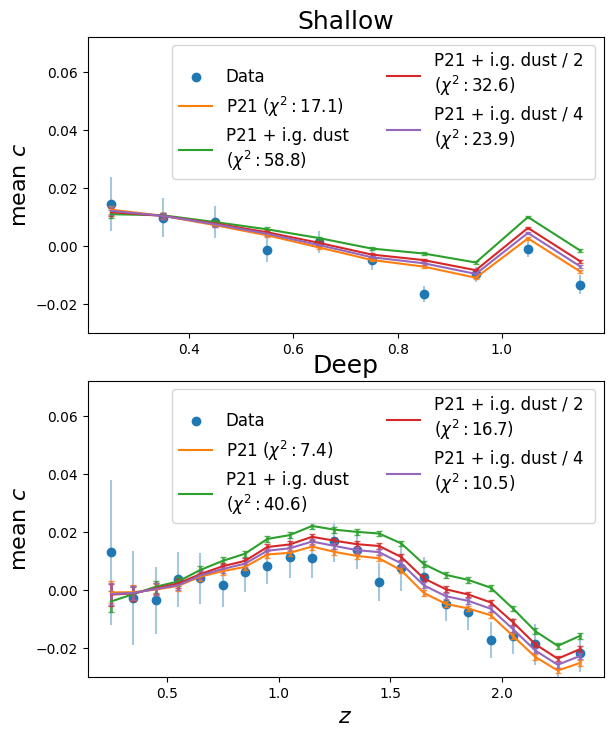

In [40]:
# fig = plt.figure(figsize=(6,8))

# ax1 = fig.add_axes([0.08, 0.52, 0.86, 0.37])
# plt.title("Shallow",fontsize=18)
# plot_c_vs_z(mz[0:len(sdc)],sdc,cerr=sdc_s,label='Data',sim=False)
# plot_c_vs_z(mz[0:len(sdc)],np.array(ssc2),cerr=1*np.array(ssc_s2),label=f'P21 ($\chi^2:{chi2(sdc,ssc2,sdc_s):.1f}$)',color='C1')
# plot_c_vs_z(mz[0:len(sdc)],np.array(ssc3),cerr=np.array(ssc_s3),label=f'P21 + i.g. dust \n($\chi^2:{chi2(sdc,ssc3,sdc_s):.1f}$)',color='C2')

# plot_c_vs_z(mz[0:len(sdc)],np.array(ssc4),cerr=np.array(ssc_s4),label=f'P21 + i.g. dust / 2 \n($\chi^2:{chi2(sdc,ssc4,sdc_s):.1f}$)',color='C3')
# plot_c_vs_z(mz[0:len(sdc)],np.array(ssc5),cerr=np.array(ssc_s5),label=f'P21 + i.g. dust / 4 \n($\chi^2:{chi2(sdc,ssc5,sdc_s):.1f}$)',color='C4')
# plt.xlabel("")
# plt.legend(loc='upper right',fontsize=12,ncol=2)
# plt.ylim(-0.03,0.072)
# # plt.xlim(0,1)

# ax2 = fig.add_axes([0.08, 0.09, 0.86, 0.37])
# plt.title("Deep",fontsize=18)
# plot_c_vs_z(mz[0:len(ddc)],ddc,cerr=ddc_s,label='Data',sim=False)
# plot_c_vs_z(mz[0:len(ddc)],np.array(dsc2),cerr=dsc_s2,label=f'P21 ($\chi^2:{chi2(ddc,dsc2,ddc_s):.1f}$)',color='C1')
# plot_c_vs_z(mz[0:len(ddc)],np.array(dsc3),cerr=dsc_s3,label=f'P21 + i.g. dust \n($\chi^2:{chi2(ddc,dsc3,ddc_s):.1f}$)',color='C2')

# plot_c_vs_z(mz[0:len(ddc)],np.array(dsc4),cerr=dsc_s4,label=f'P21 + i.g. dust / 2 \n($\chi^2:{chi2(ddc,dsc4,ddc_s):.1f}$)',color='C3')
# plot_c_vs_z(mz[0:len(ddc)],np.array(dsc5),cerr=dsc_s5,label=f'P21 + i.g. dust / 4 \n($\chi^2:{chi2(ddc,dsc5,ddc_s):.1f}$)',color='C4')
# plt.legend(loc='upper right',fontsize=12,ncol=2)
# # ax2.get_legend().remove()
# plt.ylim(-0.03,0.072)
# # plt.xlim(0,1)

# # plt.savefig("pngs/DES_compare_c_vs_z.png",bbox_inches='tight')
# # plt.savefig("pdfs/DES_compare_c_vs_z.pdf",bbox_inches='tight')
# plt.show()